# House Prices - An Overview of Encoding Techniques

#### Ntirenganya Cynthia

This notebook applies 4 different encoding techniques to the house prices dataset (`train.csv`) and compares how each one (a "pathway") affects regression performance.

Goal: predict `SalePrice` for houses in Ames, Iowa, using each encoding pathway with a `Ridge` regression model.

Plan:
1. Import libraries
2. Load and explore the data
3. Identify ordinal, nominal, and numeric columns
4. Build a reusable evaluation function
5. Method 1: Label encoding
6. Method 2: OneHot encoding
7. Method 3: Encoding categories with dataset statistics
8. Method 4: K-Fold target encoding
9. Summary: compare model performance across all four

## 1. Import libraries

Note: the starter template imports `LogisticRegression` and `accuracy_score`, which are for classification. Since we're predicting a continuous price (regression), we use `Ridge` regression and RMSE instead — the encoding techniques themselves work the same way regardless of which model consumes them.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.model_selection import train_test_split, KFold
from sklearn.linear_model import Ridge
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_squared_error

pd.set_option('display.max_columns', 100)
np.random.seed(42)

## 2. Load the data

In [2]:
df_train = pd.read_csv('/home/student/DAS/train.csv')
print('Shape:', df_train.shape)
df_train.head(5)

Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

## 3. Look at the target

`SalePrice` is right-skewed. We predict its log-transformed version instead — every method below is scored against `SalePrice_log` using RMSE (lower is better).

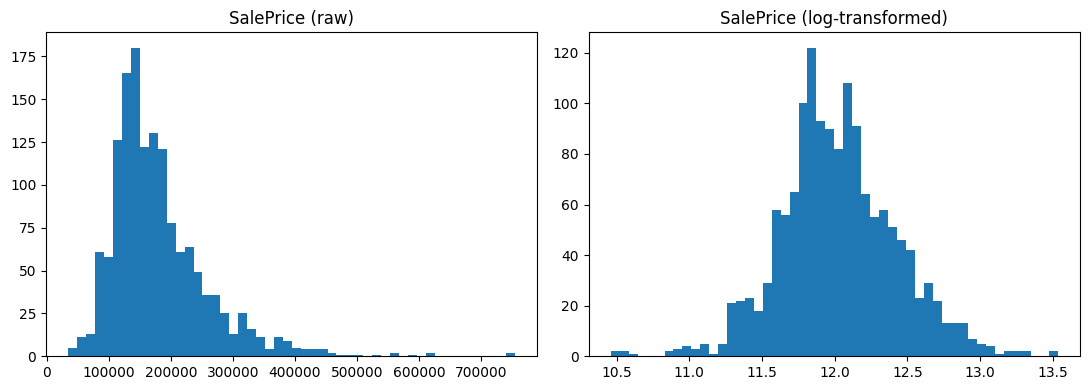

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df_train['SalePrice'], bins=50)
axes[0].set_title('SalePrice (raw)')
axes[1].hist(np.log1p(df_train['SalePrice']), bins=50)
axes[1].set_title('SalePrice (log-transformed)')
plt.tight_layout()
plt.show()

## 4. Identify column types

- **Ordinal** — columns with a genuine rank, taken from `data_description.txt` (e.g. quality ratings Poor → Excellent)
- **Nominal** — columns with no natural order (e.g. `Neighborhood`, `SaleType`)
- **Numeric** — everything already numeric

In [5]:
target = 'SalePrice'
id_col = 'Id'

categorical_cols = df_train.select_dtypes(include='object').columns.tolist()

quality_scale = ['Po', 'Fa', 'TA', 'Gd', 'Ex']

quality_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC',
                'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond']


ordinal_maps = {col: quality_scale for col in quality_cols}
ordinal_maps['PoolQC'] = ['Fa', 'TA', 'Gd', 'Ex']
ordinal_maps['BsmtExposure'] = ['No', 'Mn', 'Av', 'Gd']
ordinal_maps['BsmtFinType1'] = ['Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ']
ordinal_maps['BsmtFinType2'] = ['Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ']
ordinal_maps['GarageFinish'] = ['Unf', 'RFn', 'Fin']
ordinal_maps['LandSlope'] = ['Sev', 'Mod', 'Gtl']
ordinal_maps['LotShape'] = ['IR3', 'IR2', 'IR1', 'Reg']
ordinal_maps['PavedDrive'] = ['N', 'P', 'Y']


ordinal_cols = list(ordinal_maps.keys())
nominal_cols = [c for c in categorical_cols if c not in ordinal_cols]


print(f'{len(categorical_cols)} categorical columns total')
print(f'{len(ordinal_cols)} ordinal columns:', ordinal_cols)
print(f'{len(nominal_cols)} nominal columns:', nominal_cols)

43 categorical columns total
17 ordinal columns: ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'GarageFinish', 'LandSlope', 'LotShape', 'PavedDrive']
26 nominal columns: ['MSZoning', 'Street', 'Alley', 'LandContour', 'Utilities', 'LotConfig', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation', 'Heating', 'CentralAir', 'Electrical', 'Functional', 'GarageType', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


In [6]:
numeric_base = df_train.drop(columns=categorical_cols + [target, id_col]).fillna(0)
y = np.log1p(df_train[target])
print('numeric_base shape:', numeric_base.shape)

numeric_base shape: (1460, 36)


## 5. A reusable evaluation function

One function handles every pathway: split the data, train a `Ridge` model, predict, and report RMSE in log-space.

In [7]:
results = []

def evaluate(X, y, label):
    start = time.time()
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    model = Ridge()
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    elapsed = time.time() - start

    print(f'{label:<40} RMSE(log): {rmse:.4f}   time: {elapsed:.2f}s')
    return {'pathway': label, 'rmse': rmse, 'time_sec': elapsed}

## 6. Method 1: Label encoding

Here we map ordinal columns to their rank number (Po=0, Fa=1, ... Ex=4), preserving their real order. Nominal columns (no real order) get an arbitrary integer id via `LabelEncoder` — simple, but risks implying an order that isn't there.

In [8]:
X1 = df_train[nominal_cols + ordinal_cols].copy().fillna('Missing')

for col in ordinal_cols:
    scale = ordinal_maps[col]
    X1[col] = X1[col].apply(lambda v: scale.index(v) if v in scale else -1)

for col in nominal_cols:
    X1[col] = LabelEncoder().fit_transform(X1[col].astype(str))

X1 = pd.concat([numeric_base, X1], axis=1)
print('Shape:', X1.shape)
results.append(evaluate(X1, y, 'Method 1: Label encoding'))

Shape: (1460, 79)
Method 1: Label encoding                 RMSE(log): 0.1489   time: 0.01s


## 7. Method 2: OneHot encoding

Every category becomes its own 0/1 column. No order is assumed for any column, so it's a safe baseline but it can create a lot of columns when a feature has many categories.

In [9]:
X2 = df_train[nominal_cols + ordinal_cols].copy().fillna('Missing')
X2 = pd.get_dummies(X2, drop_first=True)
X2 = pd.concat([numeric_base, X2], axis=1)
print('Shape:', X2.shape)
results.append(evaluate(X2, y, 'Method 2: OneHot encoding'))

Shape: (1460, 260)
Method 2: OneHot encoding                RMSE(log): 0.1382   time: 0.01s


## 8. Method 3: Encoding categories with dataset statistics

Each category is replaced by a statistic computed from the dataset itself — here, how many times it appears (frequency/count). Cheap and keeps column count low, but two unrelated categories that happen to be equally common get the same encoded value.

In [10]:
X3 = df_train[nominal_cols + ordinal_cols].copy().fillna('Missing')

for col in X3.columns:
    freq_map = X3[col].value_counts()
    X3[col] = X3[col].map(freq_map)

X3 = pd.concat([numeric_base, X3], axis=1)
print('Shape:', X3.shape)
results.append(evaluate(X3, y, 'Method 3: Dataset statistics (count/frequency)'))

Shape: (1460, 79)
Method 3: Dataset statistics (count/frequency) RMSE(log): 0.1441   time: 0.01s


## 9. Method 4: K-Fold target encoding

Each category is replaced by the average `SalePrice_log` for that category — this directly encodes "houses like this tend to sell for X", which is powerful. Computing that average from the *whole* dataset would leak information from the target into the features, so each fold's encoding is computed only from the *other* folds — a row never sees its own target value baked into its encoding.

In [11]:
X4 = df_train[nominal_cols + ordinal_cols].copy().fillna('Missing')

kf = KFold(n_splits=5, shuffle=True, random_state=42)
global_mean = y.mean()

for col in X4.columns:
    
    encoded_col = pd.Series(index=X4.index, dtype=float)
    for train_idx, val_idx in kf.split(X4):
        
        fold_means = y.iloc[train_idx].groupby(X4[col].iloc[train_idx]).mean()
        encoded_col.iloc[val_idx] = X4[col].iloc[val_idx].map(fold_means)
        
    X4[col] = encoded_col.fillna(global_mean)

X4 = pd.concat([numeric_base, X4], axis=1)

print('Shape:', X4.shape)
results.append(evaluate(X4, y, 'Method 4: K-Fold Target Encoding'))

Shape: (1460, 79)
Method 4: K-Fold Target Encoding         RMSE(log): 0.1372   time: 0.01s


## 10. Summary

Lower RMSE (log scale) is better.

In [12]:
summary = pd.DataFrame(results).sort_values('rmse').reset_index(drop=True)
summary

,pathway,rmse,time_sec
0,Method 4: K-Fold Target Encoding,0.137161,0.005700
1,Method 2: OneHot encoding,0.138205,0.014676
2,Method 3: Dataset statistics (count/frequency),0.144107,0.006044
3,Method 1: Label encoding,0.148873,0.006017


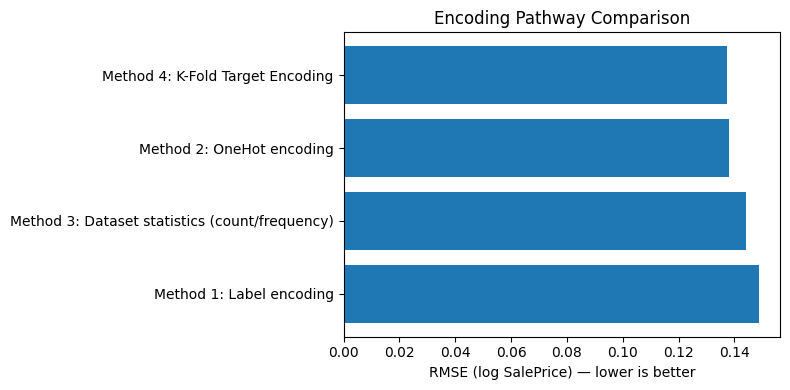

In [13]:
plt.figure(figsize=(8, 4))
plt.barh(summary['pathway'], summary['rmse'])
plt.xlabel('RMSE (log SalePrice) — lower is better')
plt.title('Encoding Pathway Comparison')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

- **K-Fold Target Encoding** won (RMSE 0.1371)-it directly encodes each category's relationship with `SalePrice`, a stronger signal than frequency or an arbitrary label number.
- **OneHot encoding** was a close second (0.1382) but slowest, since it creates one column per category instead of a single encoded number.
- **Dataset statistics (count/frequency)** placed third (0.1441)- how often a category appears says nothing about price on its own.
- **Label encoding** was weakest (0.1488)-arbitrary integers on nominal columns like `Neighborhood` risk implying a false order.
- Takeaway: respecting a column's true structure (ordinal vs. nominal) mattered more than how compact the encoding was.